# 01 · Meet the Qubit 🌐
### Quantum Technologies Club Workshop · *Qiskit from zero*

Welcome! In this notebook you'll:

1. See what **Qiskit** is and run a quantum program in ~6 lines.
2. Meet the **qubit** and draw it as an arrow on a sphere (the **Bloch sphere**).
3. Play with **quantum gates** and *watch* what each one does to the arrow.

No physics or maths background needed. If you can press **Shift + Enter**, you're qualified.

> **How to use a notebook:** grey boxes are *code cells*. Click one and press **Shift + Enter** to run it.
> Run cells **top to bottom**. If something breaks: *Runtime/Kernel → Restart* and run from the top again.

In [1]:
# ⚙️ SETUP: run this cell first (Shift + Enter)
# On Google Colab (or any fresh computer) this installs Qiskit automatically. Takes ~30 s the first time.
try:
    import qiskit, qiskit_aer, qiskit_ibm_runtime
except ImportError:
    %pip install -q qiskit qiskit-aer qiskit-ibm-runtime pylatexenc matplotlib ipywidgets
    import qiskit, qiskit_aer, qiskit_ibm_runtime

import numpy as np
import matplotlib.pyplot as plt
print("✅ Qiskit", qiskit.__version__, "| Aer", qiskit_aer.__version__, "| ready to go!")

✅ Qiskit 2.6.2 | Aer 0.18.2 | ready to go!


## 1 · What is Qiskit?

**Qiskit** (say *"kiss-kit"*) is a free, open-source Python toolkit made by IBM for programming quantum computers.

With Qiskit you:

| Step | What it means | In Qiskit |
|---|---|---|
| 🧱 **Build** | Draw a *quantum circuit*: qubits + gates + measurements | `QuantumCircuit` |
| 🛠️ **Optimize** | Translate it into the gates a real chip understands | `transpile` / pass managers |
| ▶️ **Run** | On a *simulator* (your laptop) or a *real quantum computer* (IBM cloud) | `Sampler`, `Estimator` |
| 📊 **Analyze** | Look at the results, make plots | `plot_histogram`, … |

IBM calls these four steps the **Qiskit patterns**. Today we mostly live in *Build* and *Run on a simulator*; in notebook 04 you'll run on a real IBM quantum computer for free.

### 🎬 The trailer: a complete quantum program
Don't worry about understanding it yet. By the end of today you'll be able to explain every line.

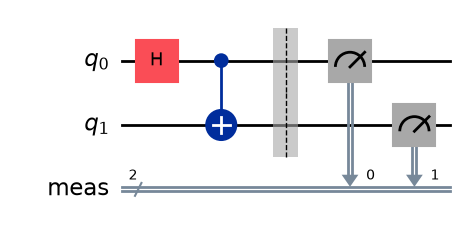

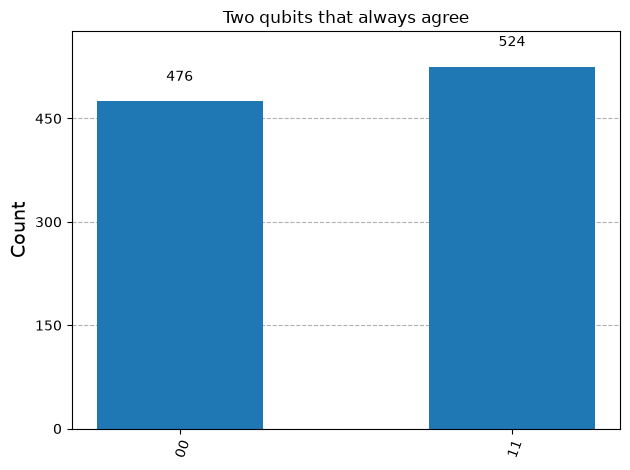

In [2]:
from qiskit import QuantumCircuit
from qiskit.primitives import StatevectorSampler
from qiskit.visualization import plot_histogram

qc = QuantumCircuit(2)      # 2 qubits
qc.h(0)                     # put qubit 0 in superposition
qc.cx(0, 1)                 # entangle qubit 0 with qubit 1
qc.measure_all()            # look at both

counts = StatevectorSampler().run([qc], shots=1000).result()[0].data.meas.get_counts()
display(qc.draw("mpl"))
plot_histogram(counts, title="Two qubits that always agree")

Two qubits, each individually random (50% `0`, 50% `1`)… yet they **always agree**: only `00` and `11` ever show up.
That's **entanglement**, and we'll build up to it step by step. Let's start with a single qubit.

---
## 2 · Bits vs. qubits

| Classical **bit** 💡 | Quantum **bit (qubit)** 🌐 |
|---|---|
| Either `0` or `1` | Can be `0`, `1`, or a **superposition** "in between" |
| Like a light switch | Like an arrow that can point anywhere on a sphere |
| Reading it doesn't change it | Measuring it gives a random `0` or `1` and erases the superposition |

Physicists write the two basic states as **|0⟩** and **|1⟩** (read *"ket zero"*, *"ket one"*). The funny brackets are just labels: think of them as name tags.

### The Bloch sphere
We picture a single qubit as an **arrow on a sphere**:

* Arrow **up** (north pole) → **|0⟩**
* Arrow **down** (south pole) → **|1⟩**
* Arrow on the **equator** → a perfect 50/50 superposition
* Anywhere else → some other mix

Every qubit in Qiskit starts at **|0⟩**. Let's look:

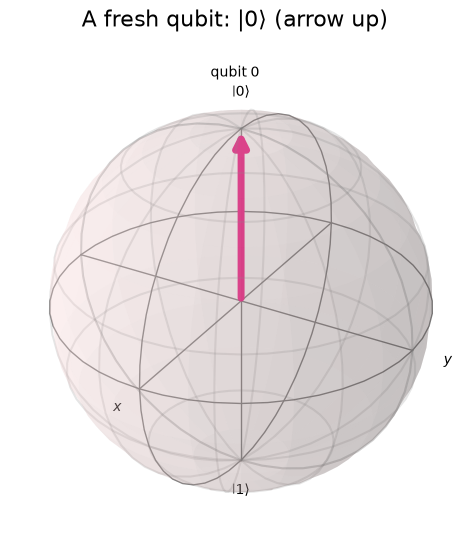

In [3]:
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_bloch_multivector

qc = QuantumCircuit(1)               # one qubit, no gates yet
state = Statevector(qc)              # ask the simulator: "what's the state right now?"
plot_bloch_multivector(state, title="A fresh qubit: |0⟩ (arrow up)")

## 3 · Gates = moves on the sphere

A **quantum gate** is an operation on qubits. On the Bloch sphere, every single-qubit gate is simply a **rotation of the arrow**.

Below is a helper that shows the arrow **after every gate** in a circuit, like a comic strip. (You don't need to understand the helper's code, just run it.)

In [4]:
# 🧰 Helper: draw the Bloch sphere after each gate (comic-strip style)
from qiskit.visualization import plot_bloch_vector

def bloch_xyz(state):
    """(x, y, z) coordinates of a single-qubit state's arrow."""
    from qiskit.quantum_info import SparsePauliOp
    return [np.real(state.expectation_value(SparsePauliOp(p))) for p in "XYZ"]

def bloch_story(qc, title=None):
    """Show the circuit, then the Bloch sphere after each gate."""
    steps = [("start", QuantumCircuit(qc.num_qubits))]
    partial = QuantumCircuit(qc.num_qubits)
    for inst in qc.data:
        partial.append(inst)
        label = inst.operation.name.upper()
        if inst.operation.params:
            label += f"({float(inst.operation.params[0]):.2f})"
        steps.append((f"after {label}", partial.copy()))
    display(qc.draw("mpl", scale=0.8))
    fig = plt.figure(figsize=(3.2 * len(steps), 3.6))
    for i, (label, c) in enumerate(steps):
        ax = fig.add_subplot(1, len(steps), i + 1, projection="3d")
        plot_bloch_vector(bloch_xyz(Statevector(c)), ax=ax, title=label, font_size=11)
    if title:
        fig.suptitle(title, fontsize=14)
    plt.show()

print("Helper ready ✅")

Helper ready ✅


### The X gate: the quantum NOT 🔁
`X` flips **|0⟩ ↔ |1⟩**. On the sphere: a half-turn (180°) around the **x-axis**, so the arrow goes from the north pole to the south pole.

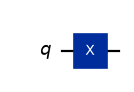

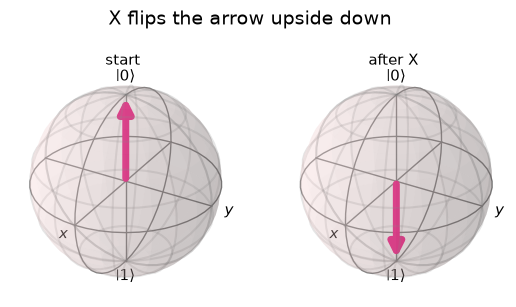

In [5]:
qc = QuantumCircuit(1)
qc.x(0)
bloch_story(qc, "X flips the arrow upside down")

### The H gate (Hadamard): the superposition maker ✨
`H` takes **|0⟩** to the **equator**, pointing along +x. This state has a special name: **|+⟩**.
If we measured it now we'd get `0` or `1` with **50/50** chance: a perfect quantum coin.

And here's the first bit of "quantum magic": apply `H` **twice** and you're **back to |0⟩**. A coin flipped twice returns to heads, every time! (We'll see *why* in notebook 02.)

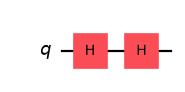

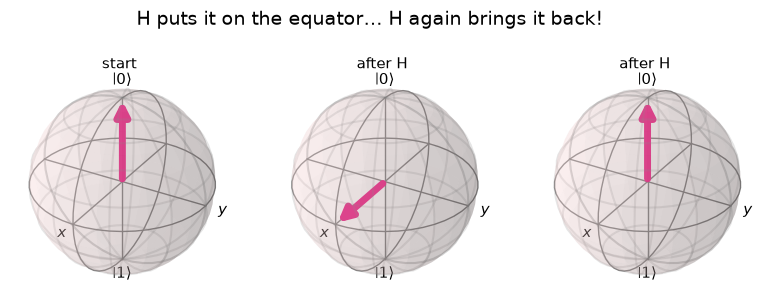

In [6]:
qc = QuantumCircuit(1)
qc.h(0)
qc.h(0)
bloch_story(qc, "H puts it on the equator… H again brings it back!")

### The Z gate: the sneaky one 🕵️
`Z` rotates 180° around the **z-axis** (the vertical axis).

* On **|0⟩** (arrow up) it does… nothing visible. Spinning a vertical arrow around a vertical axis changes nothing.
* On **|+⟩** (arrow on the equator) it swings the arrow to the *opposite side* of the equator, a state called **|−⟩**.

Both |+⟩ and |−⟩ give 50/50 when measured, so *Z's effect is invisible to a direct measurement*. This hidden "direction around the equator" is called the **phase**, and it is the secret ingredient of every quantum algorithm (spoiler: **interference**).

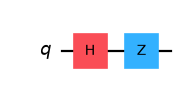

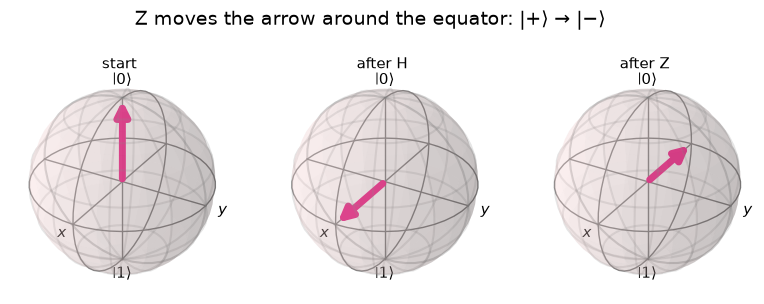

In [7]:
qc = QuantumCircuit(1)
qc.h(0)
qc.z(0)
bloch_story(qc, "Z moves the arrow around the equator: |+⟩ → |−⟩")

### Gate gallery 🖼️

| Gate | Qiskit | What it does to the arrow |
|---|---|---|
| **X** | `qc.x(0)` | 180° around the x-axis (NOT: flips 0 ↔ 1) |
| **Y** | `qc.y(0)` | 180° around the y-axis |
| **Z** | `qc.z(0)` | 180° around the z-axis (flips the phase) |
| **H** | `qc.h(0)` | Swaps the z-axis and x-axis (makes superpositions) |
| **S** | `qc.s(0)` | 90° around the z-axis |
| **T** | `qc.t(0)` | 45° around the z-axis |
| **RX/RY/RZ(θ)** | `qc.ry(theta, 0)` | Rotate by **any** angle θ (in radians) |

Let's take a little tour around the equator with `S` and `T`:

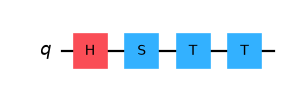

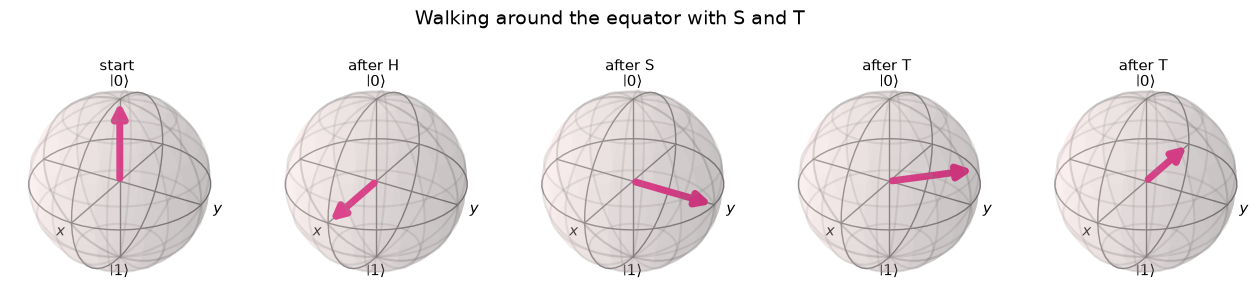

In [8]:
qc = QuantumCircuit(1)
qc.h(0)   # go to the equator
qc.s(0)   # +90°
qc.t(0)   # +45°
qc.t(0)   # +45°
bloch_story(qc, "Walking around the equator with S and T")

## 4 · Dial in any state with rotations 🎛️

`X`, `H`, `Z`… are fixed moves. **Rotation gates** let you turn the arrow by *any* angle:

* `qc.ry(theta, 0)` tilts the arrow from the north pole towards the south pole (θ = 0 → |0⟩, θ = π → |1⟩)
* `qc.rz(phi, 0)` spins it around the vertical axis

**Play with the sliders below** (on Colab/Jupyter). θ and φ are in radians: π ≈ 3.14 is half a turn.

In [9]:
# 🎛️ Interactive Bloch sphere: drag the sliders!
from qiskit.visualization import plot_histogram

def explore(theta=1.0, phi=0.0):
    qc = QuantumCircuit(1)
    qc.ry(theta, 0)
    qc.rz(phi, 0)
    state = Statevector(qc)
    probs = state.probabilities_dict()
    fig = plt.figure(figsize=(9, 3.8))
    ax1 = fig.add_subplot(1, 2, 1, projection="3d")
    plot_bloch_vector(bloch_xyz(state), ax=ax1, title=f"θ={theta:.2f}, φ={phi:.2f}")
    ax2 = fig.add_subplot(1, 2, 2)
    ax2.bar(["0", "1"], [probs.get("0", 0), probs.get("1", 0)], color=["#4C72B0", "#DD8452"])
    ax2.set_ylim(0, 1); ax2.set_ylabel("probability"); ax2.set_title("If we measured now…")
    plt.show()

try:
    from ipywidgets import interact, FloatSlider
    interact(explore,
             theta=FloatSlider(min=0, max=np.pi, step=0.05, value=1.0, description="θ (tilt)"),
             phi=FloatSlider(min=0, max=2 * np.pi, step=0.05, value=0.0, description="φ (spin)"))
except ImportError:
    explore(1.0, 0.5)   # no widgets available: just show one example

interactive(children=(FloatSlider(value=1.0, description='θ (tilt)', max=3.141592653589793, step=0.05), FloatS…

🔎 **Things to notice while sliding:**
* Tilting (θ) changes the **probabilities** of `0` and `1`.
* Spinning (φ) changes **nothing** in the bar chart. That's the invisible *phase* again.

No sliders? Here's a static version: the same arrow tilted further and further down.

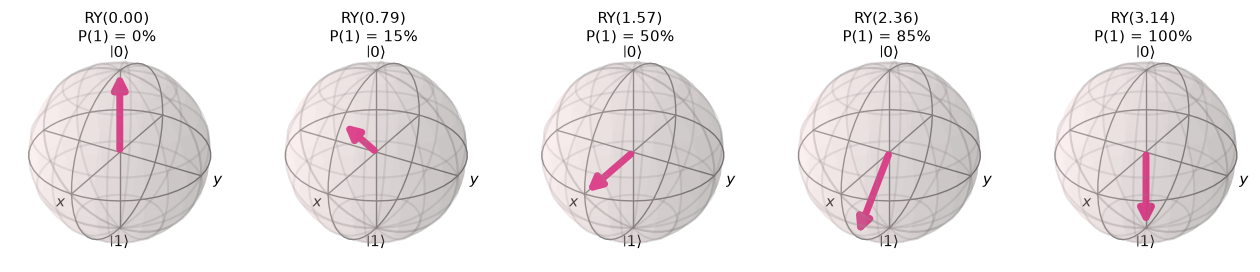

In [10]:
angles = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4, np.pi]
fig = plt.figure(figsize=(16, 3.6))
for i, th in enumerate(angles):
    qc = QuantumCircuit(1); qc.ry(th, 0)
    p1 = Statevector(qc).probabilities()[1]
    ax = fig.add_subplot(1, len(angles), i + 1, projection="3d")
    plot_bloch_vector(bloch_xyz(Statevector(qc)), ax=ax, title=f"RY({th:.2f})\nP(1) = {p1:.0%}", font_size=11)
plt.show()

## 5 · Under the hood: amplitudes (for the curious 🤓)

The arrow is a picture. The computer actually stores **two complex numbers** (called *amplitudes*):

$$|\psi\rangle = \alpha\,|0\rangle + \beta\,|1\rangle, \qquad P(0) = |\alpha|^2,\quad P(1) = |\beta|^2$$

`Statevector` lets us peek at them, something a *real* quantum computer **never** lets you do (you only get measurement results). That's one superpower of simulators.

In [11]:
qc = QuantumCircuit(1)
qc.h(0)
state = Statevector(qc)
display(state.draw("latex"))                     # pretty formula
print("amplitudes   :", np.round(state.data, 3))
print("probabilities:", {str(k): round(float(v), 3) for k, v in state.probabilities_dict().items()})

<IPython.core.display.Latex object>

amplitudes   : [0.707+0.j 0.707+0.j]
probabilities: {'0': 0.5, '1': 0.5}


`0.707` is $1/\sqrt{2}$, and $0.707^2 = 0.5$ → 50/50. ✔️

## 6 · More than one qubit

Circuits can have many qubits. `plot_bloch_multivector` draws one sphere per qubit. Note: **qubits are numbered from 0**.

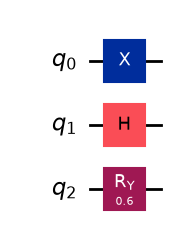

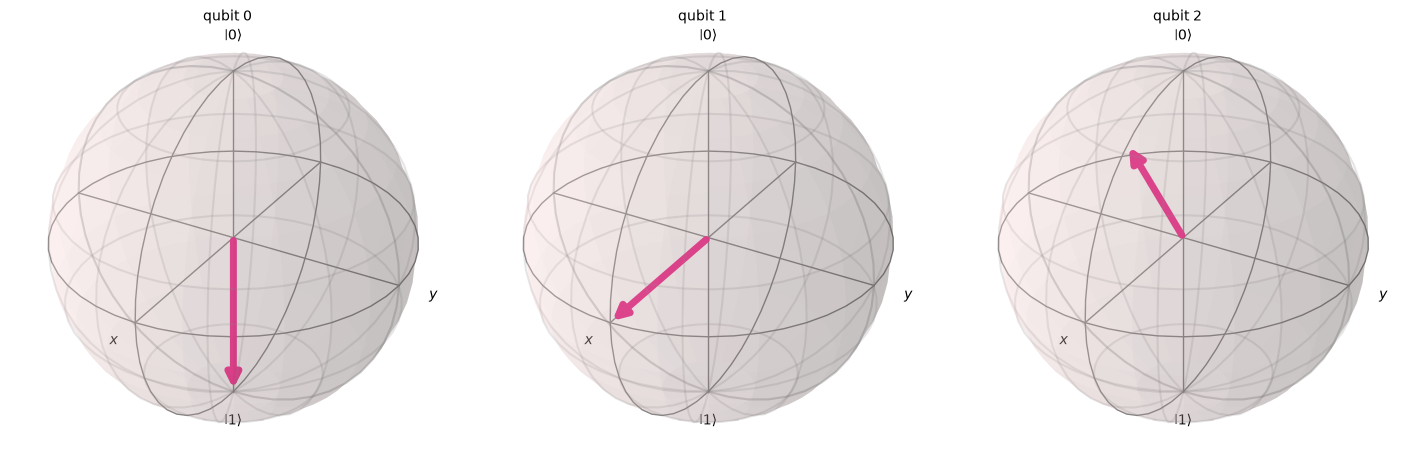

In [12]:
qc = QuantumCircuit(3)
qc.x(0)          # qubit 0 → |1⟩
qc.h(1)          # qubit 1 → equator
qc.ry(0.6, 2)    # qubit 2 → slightly tilted
display(qc.draw("mpl"))
plot_bloch_multivector(Statevector(qc))

Each qubit here has its own arrow. But remember the trailer? For **entangled** qubits, the individual arrows *disappear*: a qubit doesn't have a direction of its own any more. Try it:

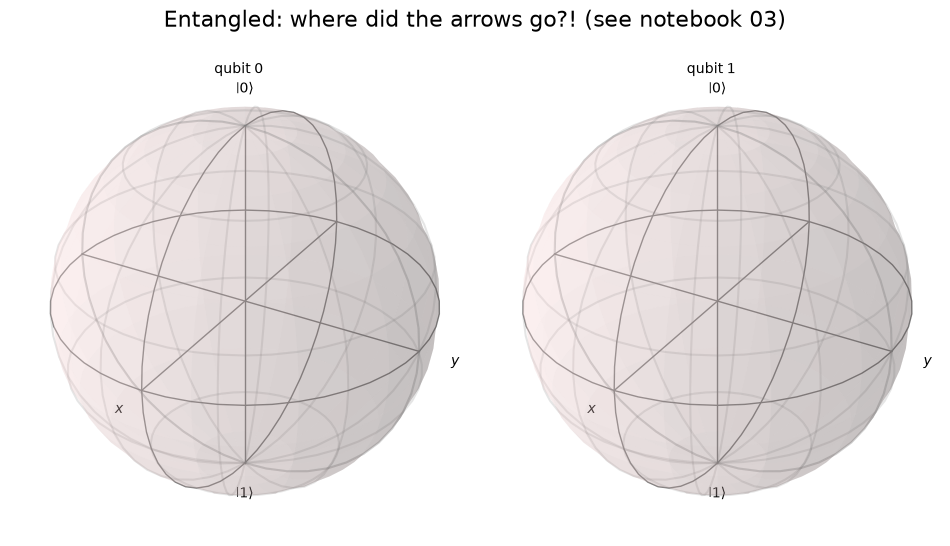

In [13]:
qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0, 1)
plot_bloch_multivector(Statevector(qc), title="Entangled: where did the arrows go?! (see notebook 03)")

---
## 🏆 Challenges
Try these in the empty cells below. Use `bloch_story(qc)` to check your answer. Solutions are hidden: click to reveal *after* trying!

**C1.** Make the arrow point **down (|1⟩)** *without* using `X`. (Hint: you've seen two other gates that can do it.)

**C2.** Make the arrow point along **−x** (the |−⟩ state) using only `X` and `H`.

**C3.** Using `ry`, prepare a qubit that gives `1` with **25%** probability. (Hint: $P(1) = \sin^2(\theta/2)$.)

**C4. ⭐** Show that `H`, then `Z`, then `H` does the same thing as `X`.

<details><summary>💡 Click for solutions</summary>

* **C1:** `qc.y(0)` or `qc.ry(np.pi, 0)`, or even `qc.h(0); qc.z(0); qc.h(0)` (see C4!)
* **C2:** `qc.x(0); qc.h(0)` (start at |1⟩ then Hadamard)
* **C3:** $\sin^2(\theta/2) = 0.25 \Rightarrow \theta = \pi/3$ → `qc.ry(np.pi/3, 0)`. Check with `Statevector(qc).probabilities_dict()`
* **C4:** `bloch_story` both circuits, or exactly: `from qiskit.quantum_info import Operator; Operator(hzh_circuit).equiv(Operator(x_circuit))` → `True`
</details>

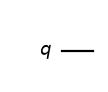

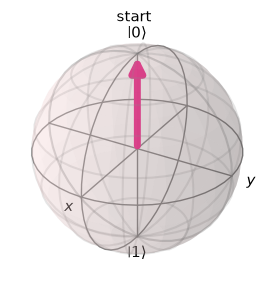

In [14]:
# ✍️ Your playground: build a circuit and look at it
qc = QuantumCircuit(1)
# qc.???(0)

bloch_story(qc)

In [15]:
# ✍️ Another playground cell

---
## ✅ Recap
* **Qiskit** = Python toolkit to *build*, *optimize*, *run* and *analyze* quantum circuits.
* A **qubit** is an arrow on the **Bloch sphere**: up = |0⟩, down = |1⟩, equator = 50/50 superposition.
* **Gates** rotate the arrow: `X` (flip), `H` (superposition), `Z`/`S`/`T` (phase), `RY`/`RZ` (any angle).
* The **phase** (direction around the equator) is invisible to measurement… but it matters. Next up!

👉 **Next: `02_measure_and_simulate.ipynb`**: rolling the quantum dice and seeing interference.